In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

In [3]:
df=pd.read_csv(r"C:\Users\chira\OneDrive\Desktop\telco-churn-mlops\data\raw\WA_Fn-UseC_-Telco-Customer-Churn.csv")
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
df.shape

(7043, 21)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [8]:
df.isna().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [10]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,3186-AJIEK,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [14]:
df.duplicated().sum()

np.int64(0)

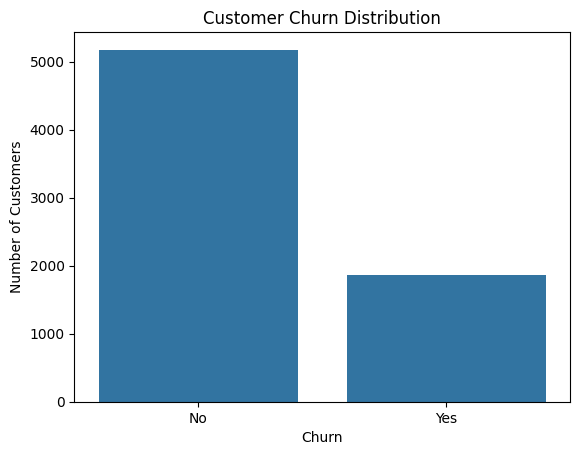

In [15]:
plt.Figure(figsize=(6,4))
sns.countplot(df,x="Churn")
plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.show()

In [17]:
print(df.columns)

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')


In [21]:
numerical_columns = []
for cat in df.columns:
    if df[cat].dtype != "object":
        numerical_columns.append(cat)


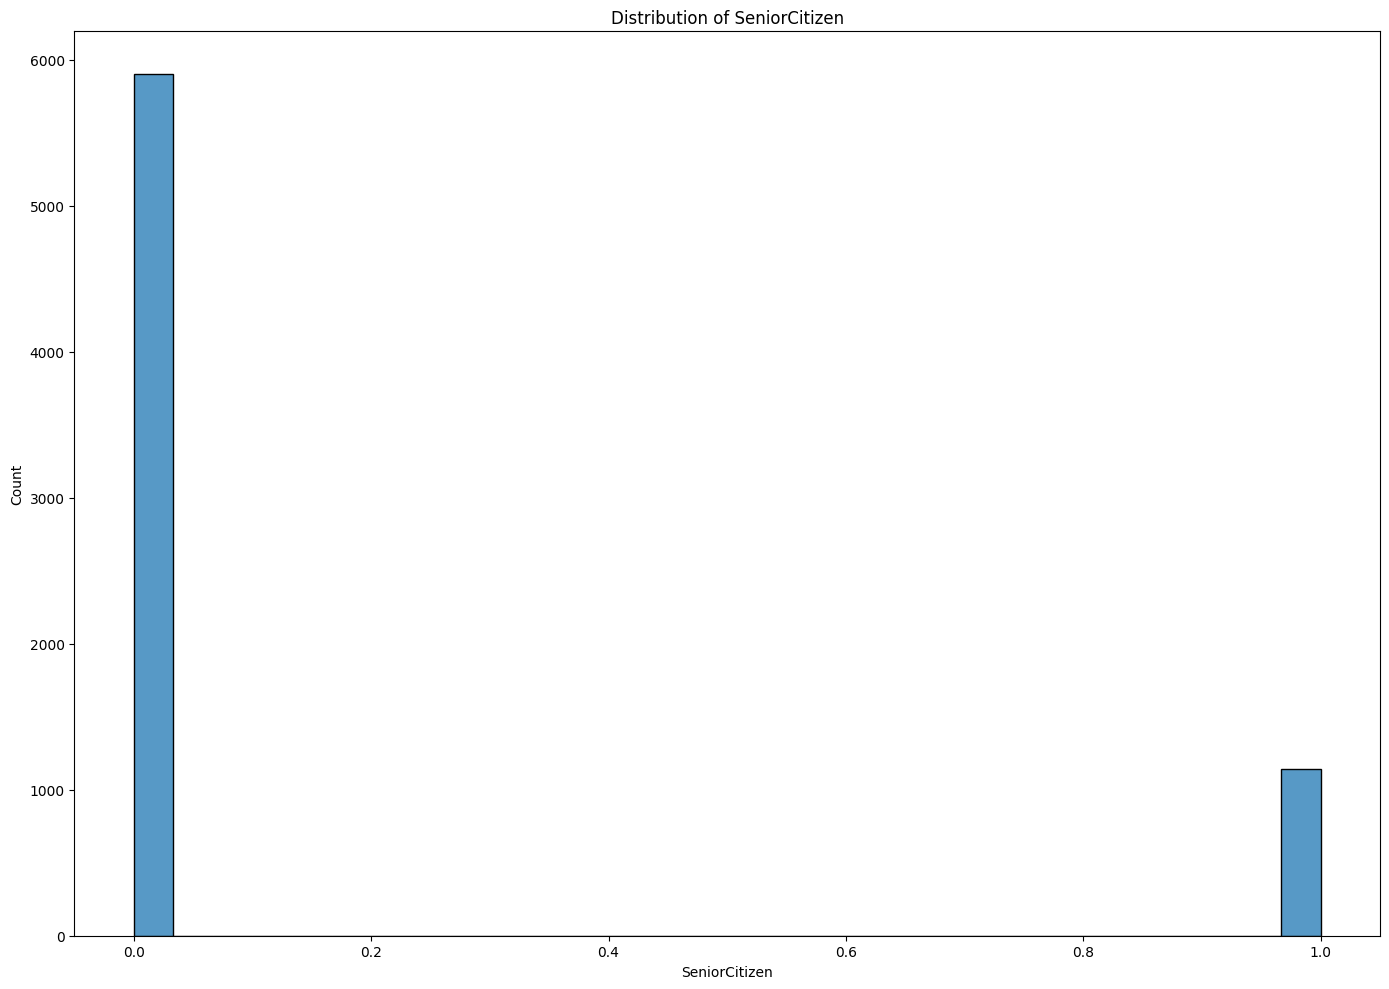

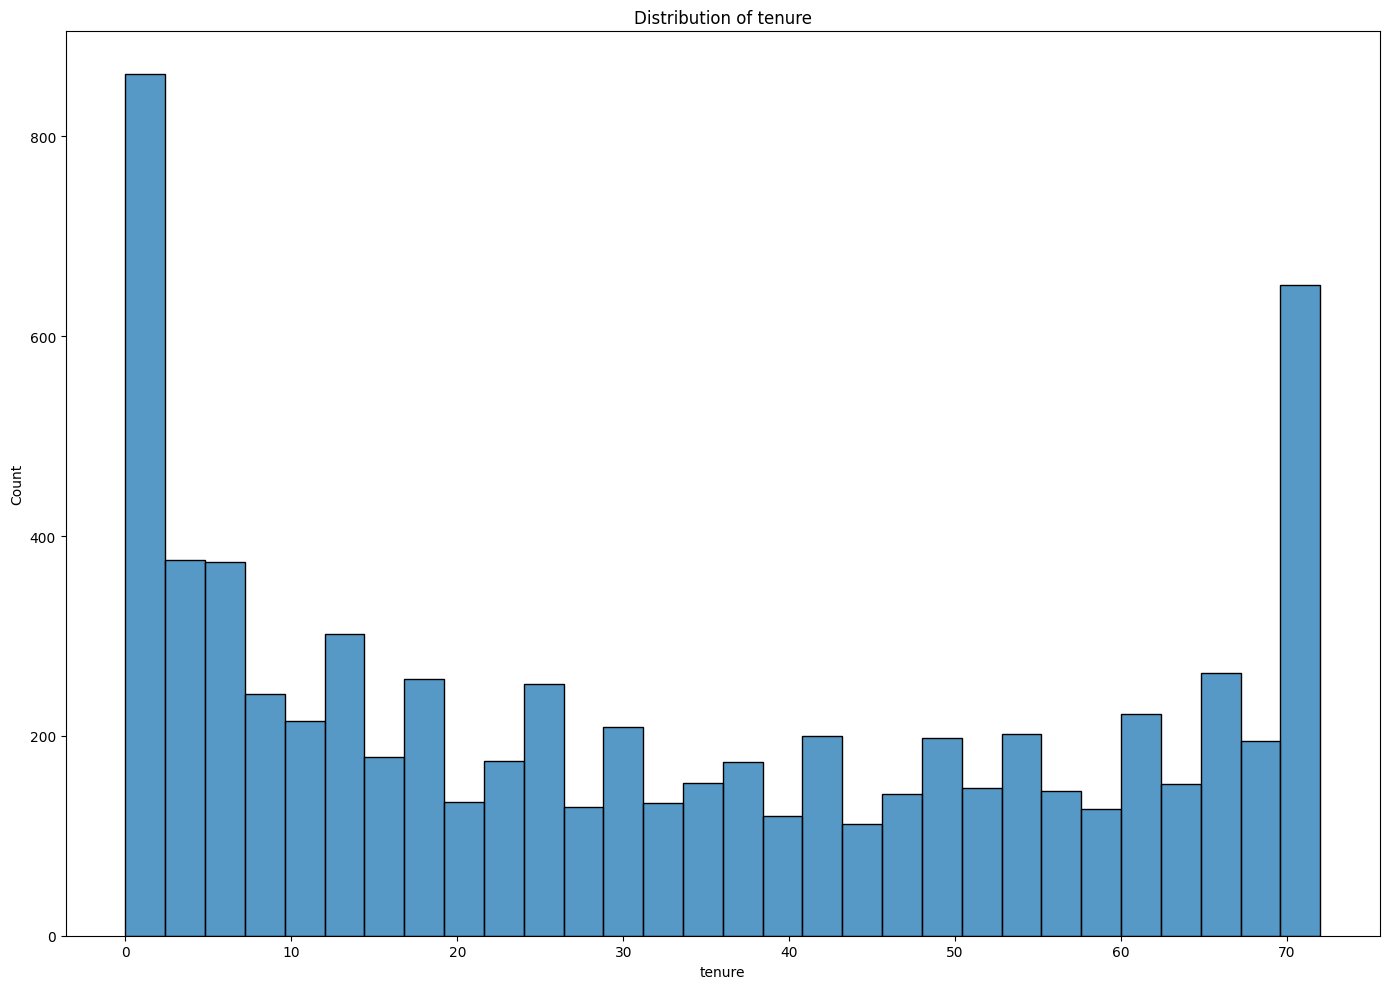

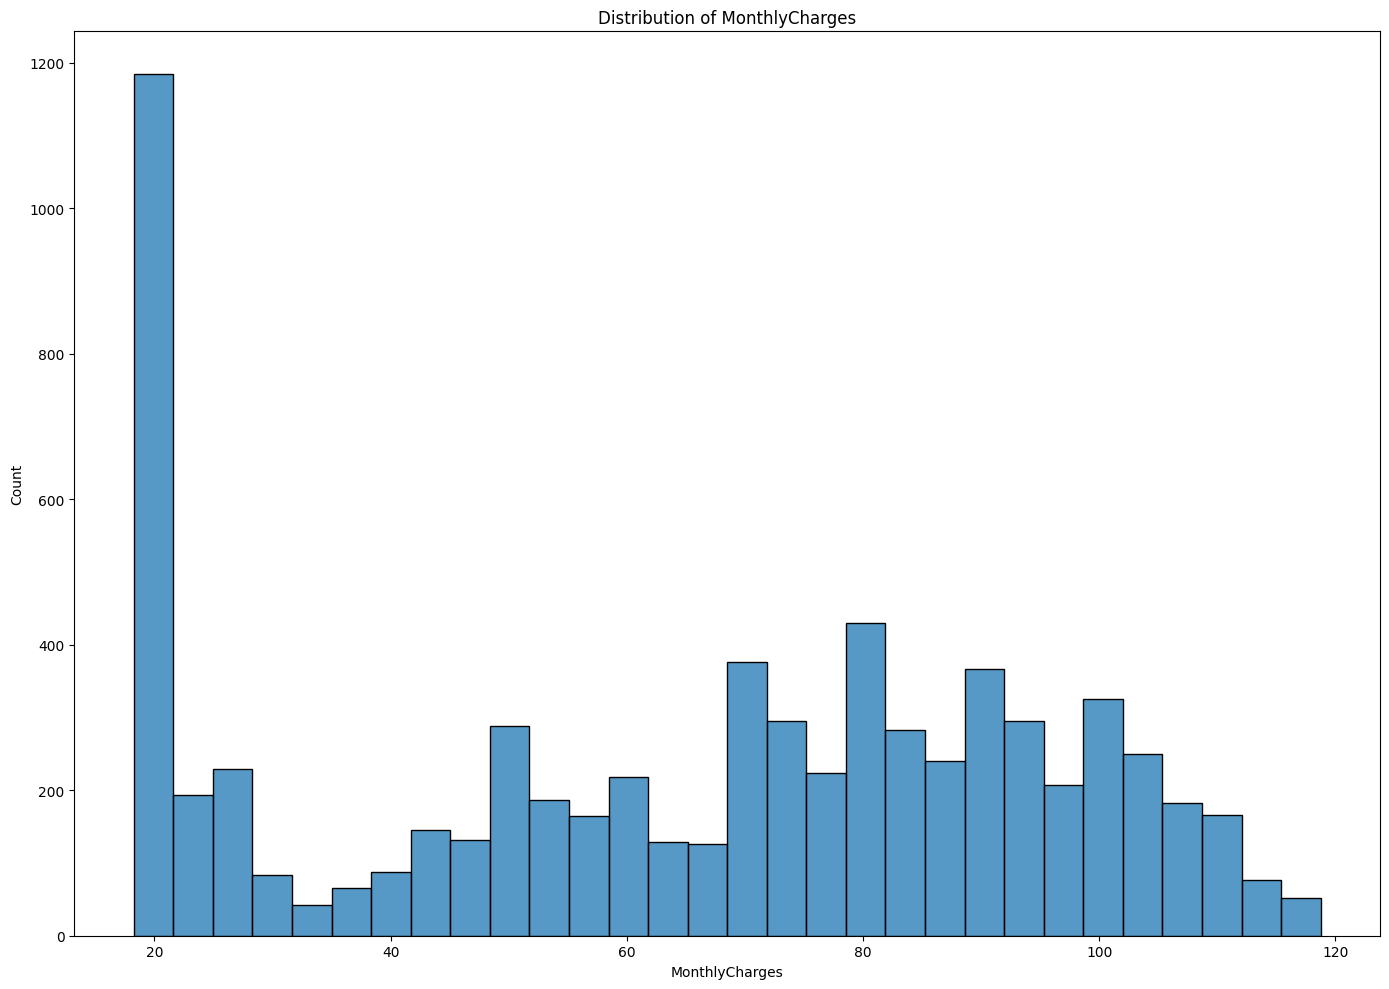

In [24]:
for col in numerical_columns:
    plt.figure(figsize=(14, 10))
    sns.histplot(data=df, x=col, bins=30)
    plt.title(f"Distribution of {col}")
    plt.tight_layout()
    plt.show()

In [25]:
categorical_columns=[]
for cat in df.columns:
    if df[cat].dtype == "object":
        categorical_columns.append(cat)

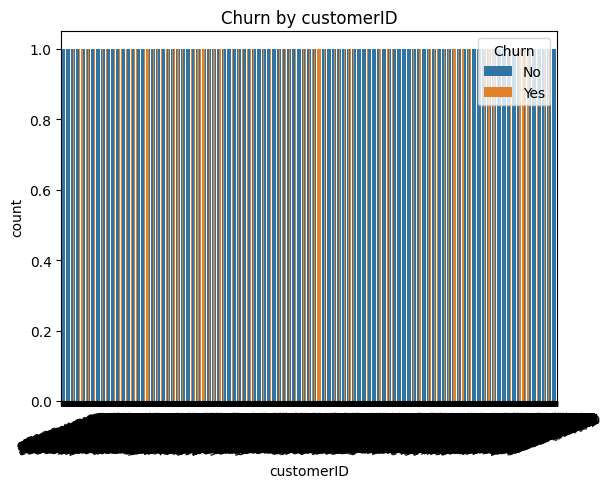

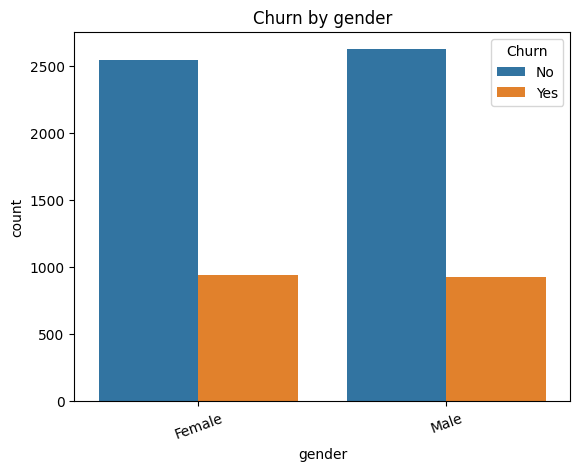

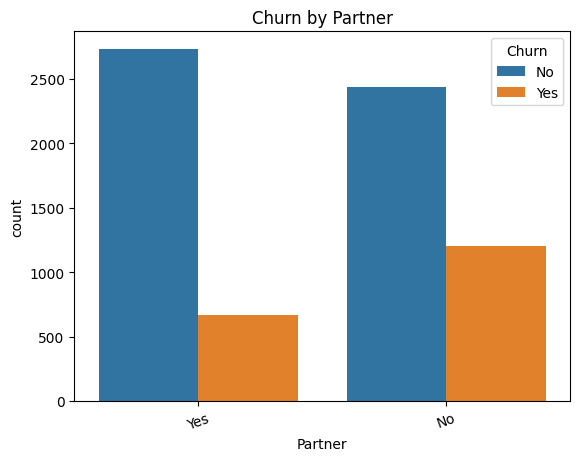

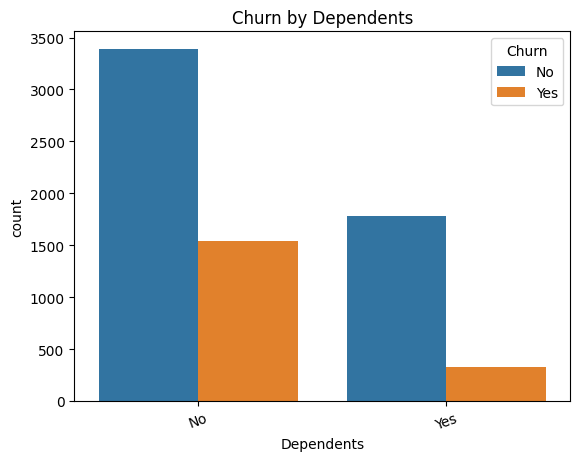

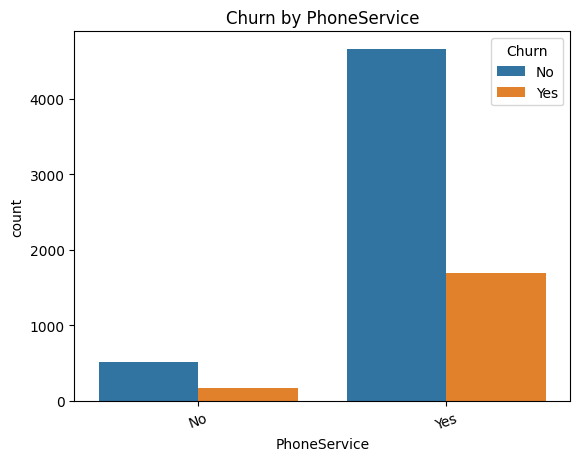

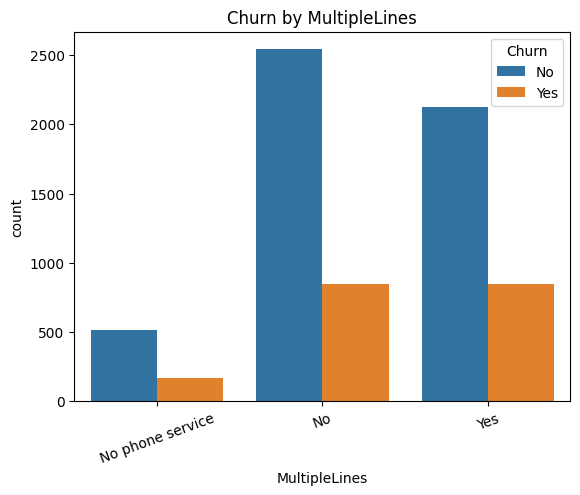

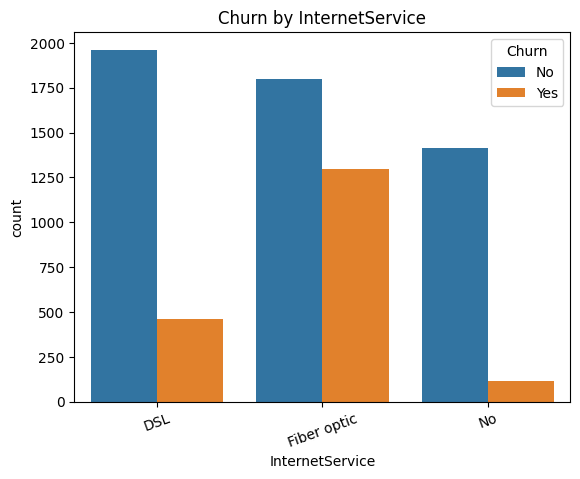

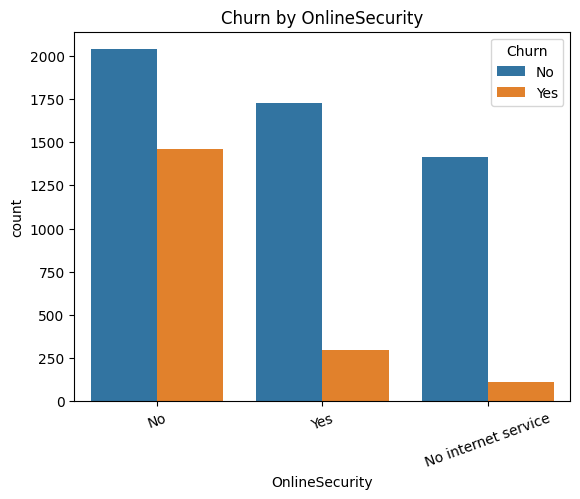

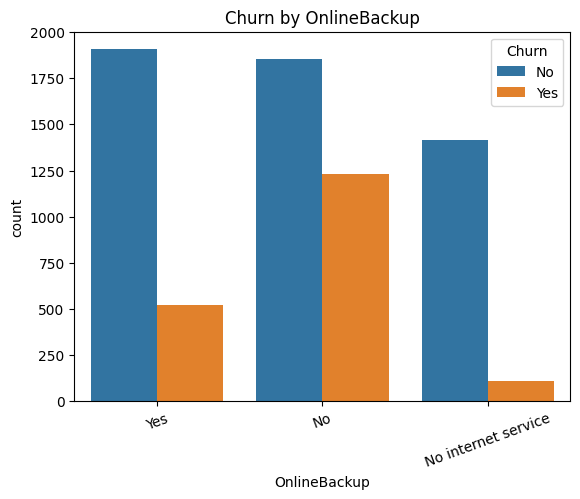

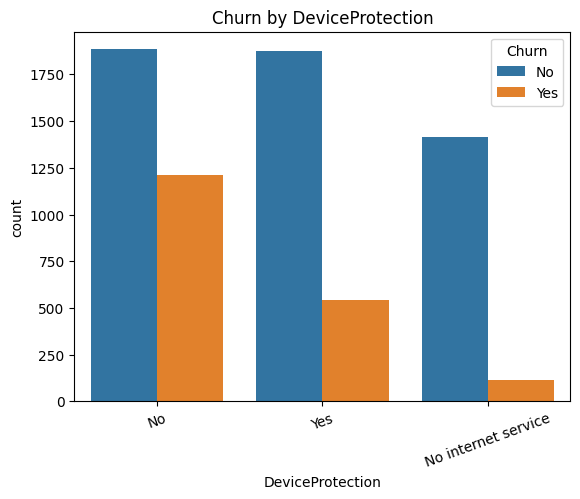

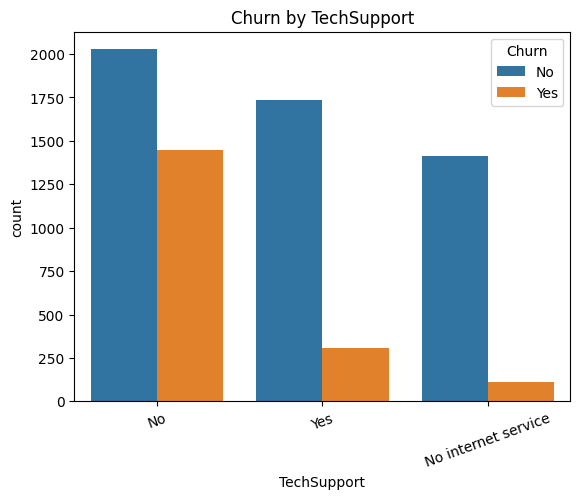

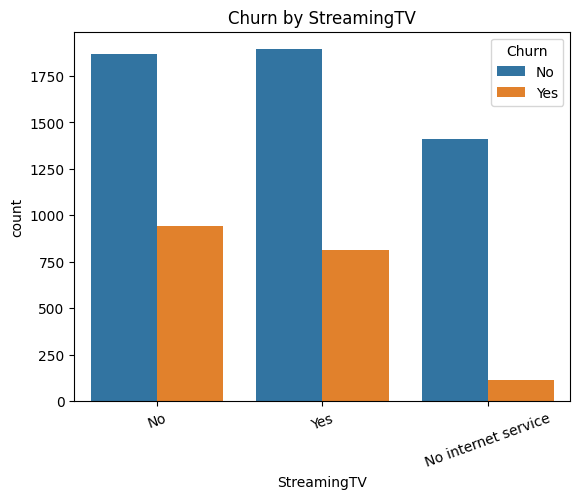

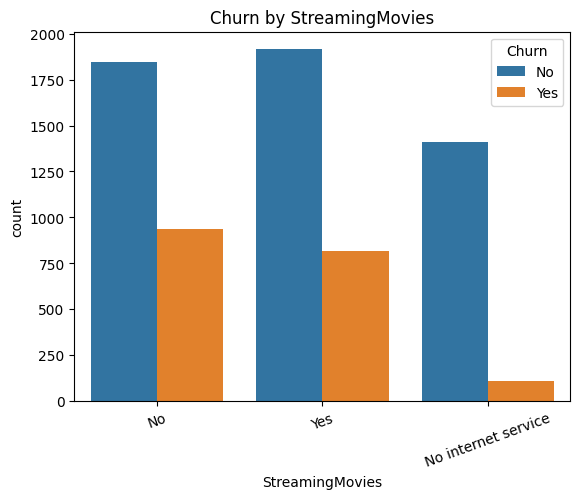

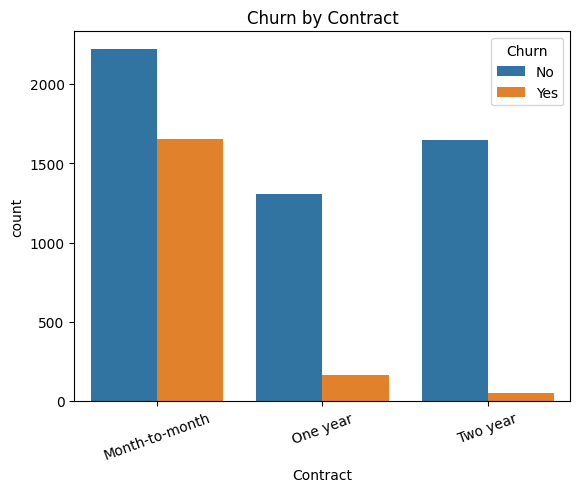

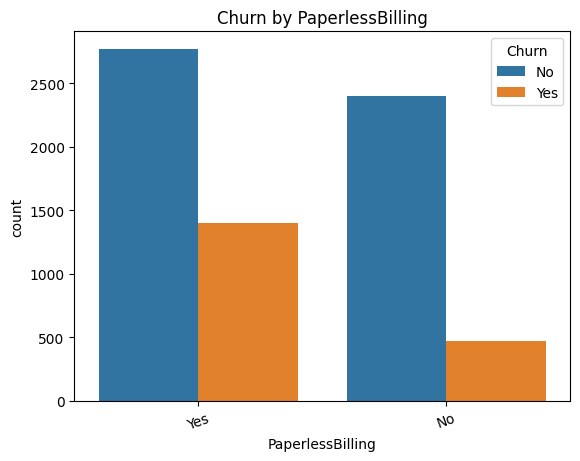

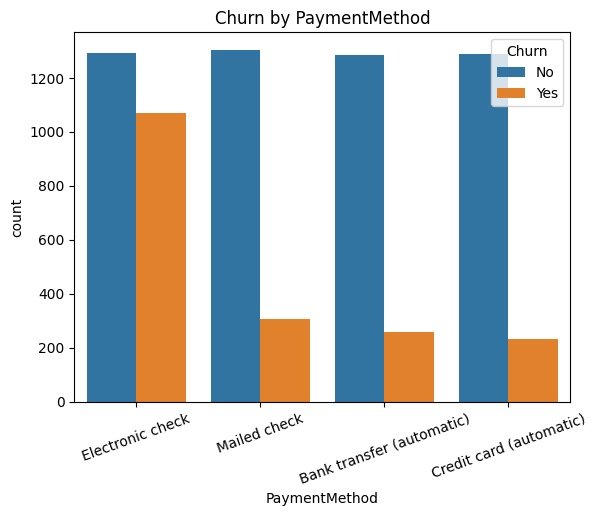

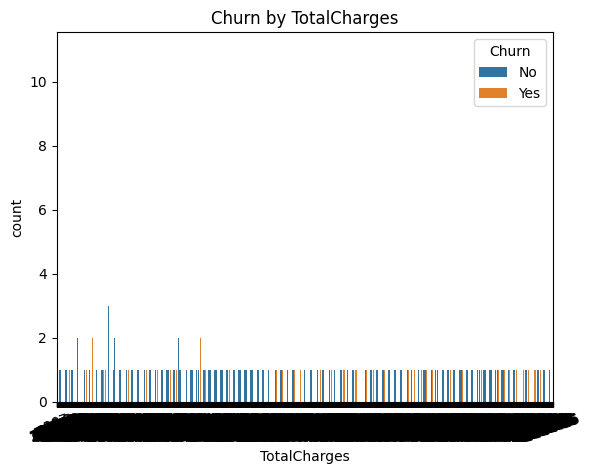

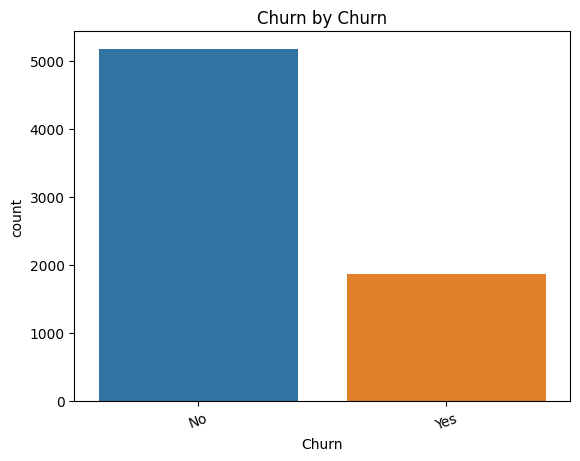

In [26]:
for col in categorical_columns:
    plt.Figure(figsize=(14, 10))
    sns.countplot(data=df,x=col,hue="Churn")
    plt.title(f"Churn by {col}")
    plt.xticks(rotation=20)

    plt.show()

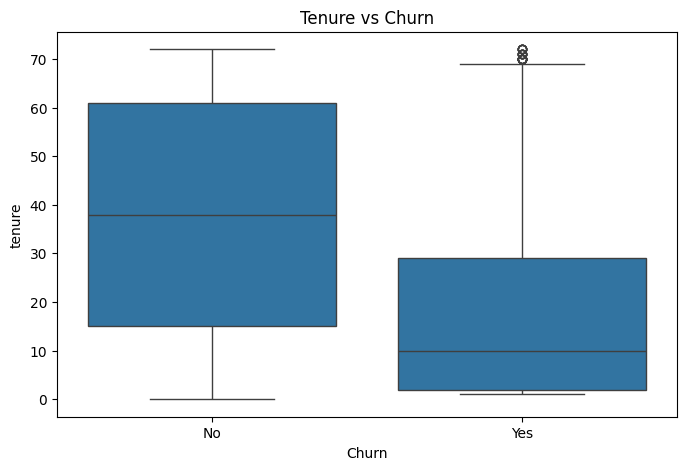

In [29]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="tenure"
)

plt.title("Tenure vs Churn")

plt.show()

In [30]:
df_corr = df.copy()

df_corr["Churn"] = df_corr["Churn"].map({
    "Yes": 1,
    "No": 0
})

In [31]:
df_corr["TotalCharges"] = pd.to_numeric(
    df_corr["TotalCharges"],
    errors="coerce"
)

In [33]:
correlation = df_corr.select_dtypes(
    include=["int64", "float64"]
).corr()

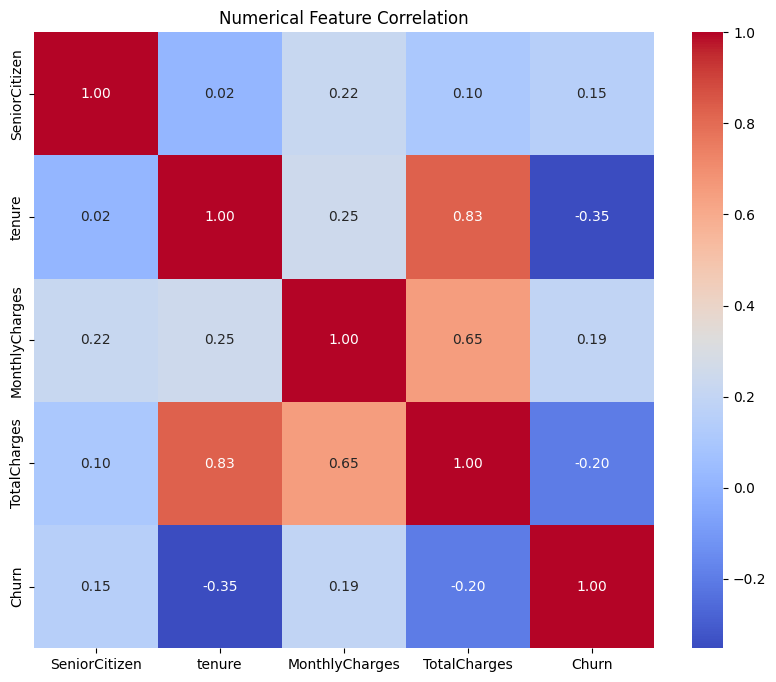

In [34]:
plt.figure(figsize=(10, 8))

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Numerical Feature Correlation")

plt.show()

In [35]:
contract_churn = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
) * 100

contract_churn

Churn,No,Yes
Contract,,
Month-to-month,57.290323,42.709677
One year,88.730482,11.269518
Two year,97.168142,2.831858


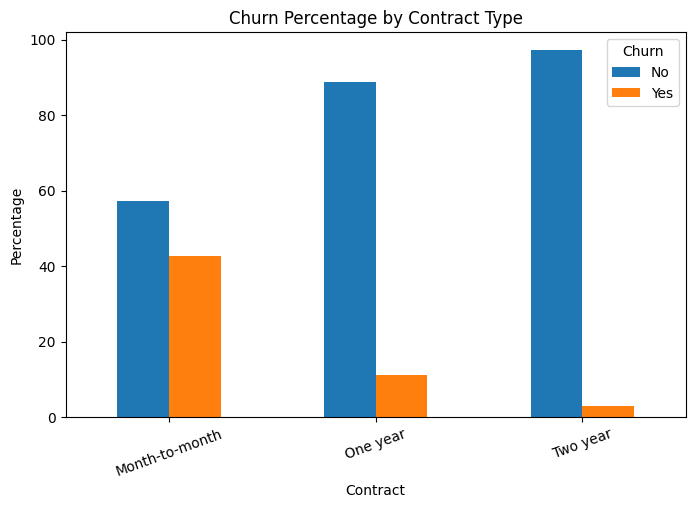

In [36]:
contract_churn.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Churn Percentage by Contract Type")
plt.ylabel("Percentage")
plt.xlabel("Contract")

plt.xticks(rotation=20)

plt.show()

In [39]:
columns = [
    "InternetService",
    "PaymentMethod",
    "TechSupport",
    "OnlineSecurity",
    "SeniorCitizen"
]


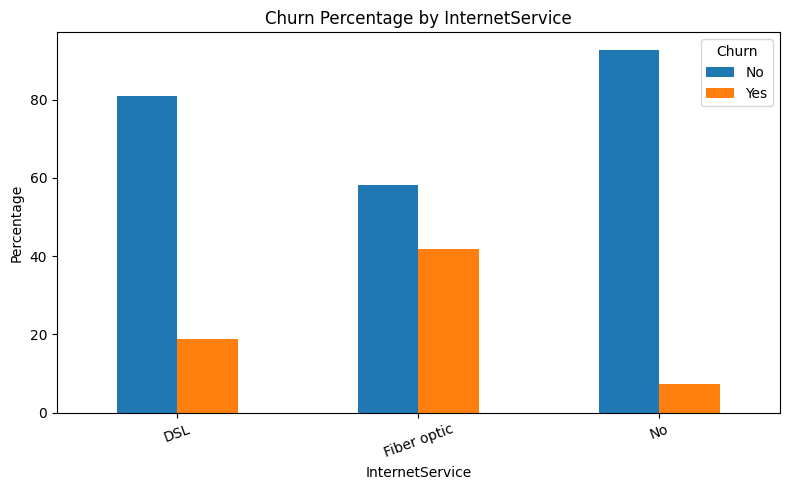

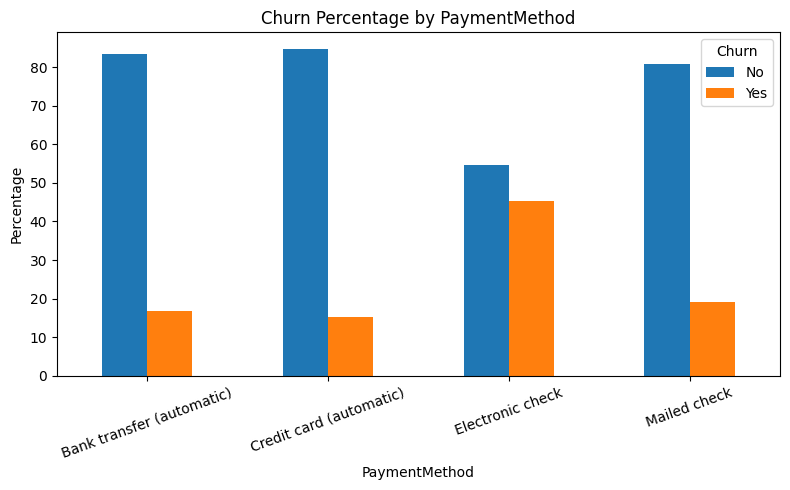

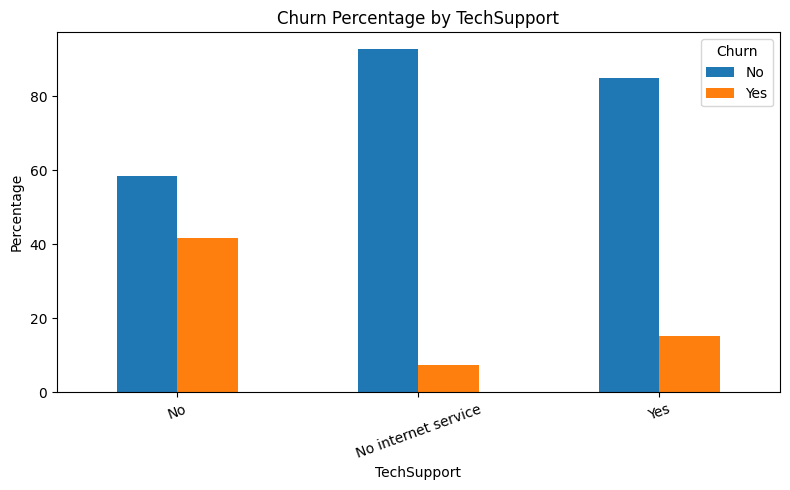

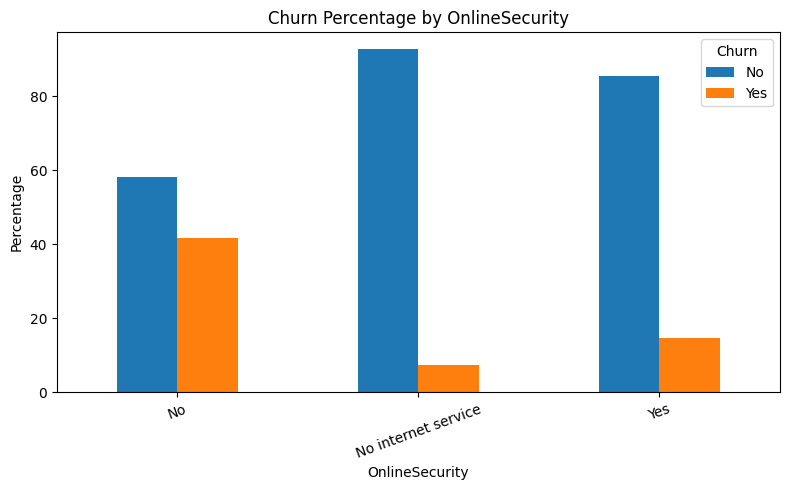

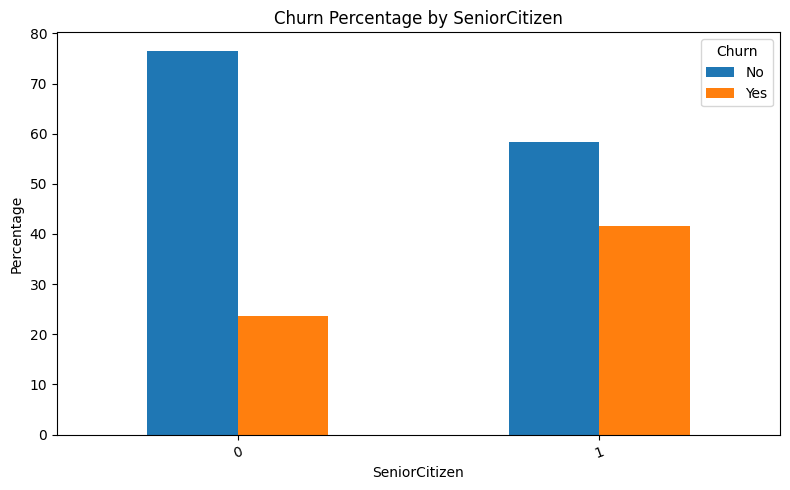

In [40]:
for col in columns:
    churn_rate = pd.crosstab(
        df[col],
        df["Churn"],
        normalize="index"
    ) * 100

    churn_rate.plot(
        kind="bar",
        figsize=(8, 5)
    )

    plt.title(f"Churn Percentage by {col}")
    plt.ylabel("Percentage")
    plt.xlabel(col)
    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.show()

## EDA Conclusions

### Dataset
- The dataset contains 7,043 customer records and 21 features.
- The target variable is `Churn`.
- The target is imbalanced, with approximately 26.5% churned customers.

### Data Quality
- `TotalCharges` requires conversion from object to numeric.
- Blank values are present in `TotalCharges`.
- `customerID` is an identifier and should not be used as a predictive feature.

### Important Churn Patterns

1. Contract type has a strong relationship with churn.
   - Month-to-month customers have substantially higher churn.
   - One-year and two-year contract customers have much lower churn.

2. Tenure has a strong relationship with churn.
   - Churned customers generally have much shorter tenure.
   - Tenure has a negative correlation with churn.

3. Internet service type is associated with churn.
   - Fiber optic customers have a substantially higher churn rate.

4. Payment method is associated with churn.
   - Electronic check customers have a particularly high churn rate.

5. Technical support and online security are associated with lower churn.
   - Customers without these services have higher churn rates.

6. Senior citizens show a higher churn rate than non-senior citizens.

7. Monthly charges show a positive relationship with churn.

### Modeling Considerations

- The target variable is imbalanced.
- Accuracy alone should not be used for model evaluation.
- Precision, recall, F1-score and ROC-AUC will be evaluated.
- Categorical variables require encoding.
- `TotalCharges` must be converted to numeric.
- `customerID` should be removed because it is an identifier.
- Preprocessing must be implemented in a reproducible pipeline to avoid data leakage.